# 04.2 KNN (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con el experimento 1 y con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma que en el experimento 1.
- Hiperparámetros: salen de la búsqueda con Optuna del experimento 2 (carpeta `04-hyperparameter-optimization-experiment-2`), con `load_best(...)`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- No usar `test`.

## Hipótesis del experimento 2

El experimento 1 dejó a KNN en macro-F1 0,534 (clasificación) y R² 0,236 (regresión). En este experimento usamos las mismas variables que el SVM del experimento 2, para comprobar si dos cambios lo mejoran y para poder comparar los dos modelos en igualdad de condiciones. Cada cambio es una hipótesis que el resultado confirmará o no.

| Cambio | Hipótesis |
|---|---|
| 1. Agregar raza, color y ciudad (`breed_main`, `color_main`, `city`) | Con más información sobre cada animal, KNN encuentra vecinos que se parecen más al animal nuevo y mejora, sobre todo al predecir los días hasta la adopción |
| 2. Edad en logaritmo (`age_log`), solo en regresión | Con la edad en logaritmo, la distancia entre animales refleja mejor cuánto se parecen en edad y mejora la regresión |

**Lo que no cambia.** Los ajustes que se buscan y sus rangos (`n_neighbors` de 3 a 200, `weights` y `p`), las variables de fecha y hora, la validación, la semilla y el número de pruebas. La búsqueda de ajustes se repite porque las variables cambian.

**Cómo se evalúan.** Si las hipótesis son correctas, esperamos que KNN supere sus resultados del experimento 1 (macro-F1 0,534 y R² 0,236), sobre todo en regresión. En clasificación podría pasar lo contrario: KNN decide por distancias entre animales, y las columnas nuevas (unas 40 más, de raza, color y ciudad) pueden diluir esa distancia. Como los cambios 1 y 2 se aplican a la vez, el resultado no permite separar cuánto aporta cada uno. Con las mismas variables, el resultado de KNN se puede comparar con el del SVM del experimento 2.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import load_best

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

/Users/klorenzoe/Documents/Personal/MUCSI/ML/mucsi-ml-animal-shelter-project/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

Las mismas variables que el SVM del experimento 2. Frente al experimento 1 se agregan raza, color y ciudad (`CAT_HIGH`) y, en regresión, la edad se usa en logaritmo (`age_log`) en lugar de `age_days`.

In [2]:
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC
FEATURES_EXP2_REG = CAT_LOW + CAT_HIGH + BINARY + [c for c in NUMERIC if c != "age_days"] + NUMERIC_LOG

print("El experimento 2 usa estas variables:")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'prior_stays', 'hour', 'month', 't_months', 'age_log']


## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 2. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [3]:
folder = "../04-hyperparameter-optimization-experiment-2"
params_clf = load_best("knn_clf", FEATURES_EXP2_CLF, folder=folder)
params_reg = load_best("knn_reg", FEATURES_EXP2_REG, folder=folder)

Ajustes cargados de knn_clf.json: {'n_neighbors': 20, 'weights': 'distance', 'p': 1}
(en la búsqueda: macro-F1 = 0.5281)
Ajustes cargados de knn_reg.json: {'n_neighbors': 27, 'weights': 'distance', 'p': 1}
(en la búsqueda: R² (en log) = 0.29)


## 1. Clasificación

Se evalúa con todos los datos. Cada fila se predice con un modelo que no la vio. Tarda cerca de un minuto.

macro-F1: 0.529  (siempre la clase más frecuente: 0.119)

                 precision    recall  f1-score   support

       Adoption       0.59      0.79      0.68     27073
     Euthanasia       0.82      0.58      0.68      4986
          Other       0.48      0.11      0.18       834
Return to Owner       0.64      0.50      0.56     11757
       Transfer       0.63      0.48      0.55     19031

       accuracy                           0.62     63681
      macro avg       0.63      0.49      0.53     63681
   weighted avg       0.63      0.62      0.61     63681



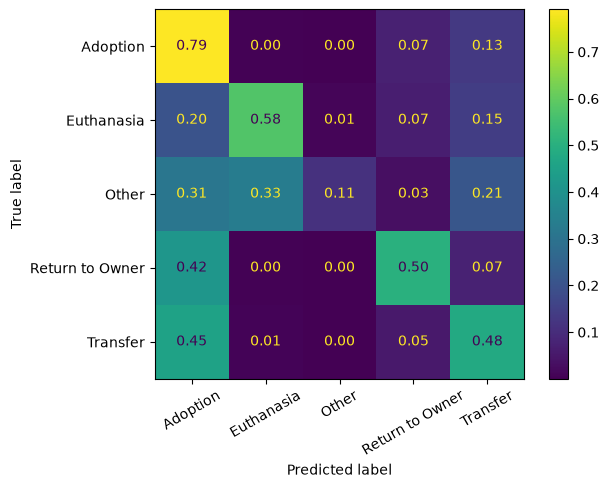

In [4]:
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF)), ("model", KNeighborsClassifier(**params_clf))])
X_clf = data[FEATURES_EXP2_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
base_clf = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_clf, y_clf, groups=groups, cv=cv)

print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}  (siempre la clase más frecuente: {f1_score(y_clf, base_clf, average='macro'):.3f})\n")
print(classification_report(y_clf, pred_clf))

ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

El error se reporta en días (`np.expm1`) y el R² en log.

In [5]:
pipe_reg = Pipeline([("prep", build_preprocessor(numeric=NUMERIC + NUMERIC_LOG, columns=FEATURES_EXP2_REG)),
                     ("model", KNeighborsRegressor(**params_reg))])
X_reg = data.loc[adopted, FEATURES_EXP2_REG]

pred_log = cross_val_predict(pipe_reg, X_reg, y_reg, groups=groups_reg, cv=cv, n_jobs=5)
base_log = cross_val_predict(DummyRegressor(strategy="median"), X_reg, y_reg, groups=groups_reg, cv=cv)

days_real = np.expm1(y_reg)
pd.DataFrame({
    "R² (log)": [r2_score(y_reg, pred_log), r2_score(y_reg, base_log)],
    "MAE (días)": [mean_absolute_error(days_real, np.expm1(pred_log)), mean_absolute_error(days_real, np.expm1(base_log))],
}, index=["KNN", "Siempre la mediana"]).round(3)

,R² (log),MAE (días)
KNN,0.290,20.471
Siempre la mediana,-0.058,24.312


## 3. Resultados frente al experimento 1 y al SVM

In [6]:
knn1 = {"Clasificación (macro-F1)": 0.534, "Regresión (R² log)": 0.236, "Regresión (MAE días)": 20.975}  # KNN, experimento 1
svm2 = {"Clasificación (macro-F1)": 0.513, "Regresión (R² log)": 0.345, "Regresión (MAE días)": 19.626}  # SVM, experimento 2
knn2 = {"Clasificación (macro-F1)": f1_score(y_clf, pred_clf, average="macro"),
        "Regresión (R² log)": r2_score(y_reg, pred_log),
        "Regresión (MAE días)": mean_absolute_error(days_real, np.expm1(pred_log))}

pd.DataFrame({"KNN experimento 1": knn1, "KNN experimento 2": knn2, "SVM experimento 2": svm2}).T.round(3)

,Clasificación (macro-F1),Regresión (R² log),Regresión (MAE días)
KNN experimento 1,0.534,0.236,20.975
KNN experimento 2,0.529,0.290,20.471
SVM experimento 2,0.513,0.345,19.626


## 4. Resultados por fold

Cada fold deja fuera un grupo distinto de animales para evaluar. Estos son los resultados de cada uno, con los mismos folds en todos los modelos, así que se pueden comparar fold por fold. No vuelve a entrenar nada: usa las predicciones de arriba.

In [7]:
rows_clf = []
for fold, (_, val) in enumerate(cv.split(X_clf, y_clf, groups), start=1):
    rows_clf.append({"fold": fold, "filas": len(val),
                     "macro-F1": f1_score(y_clf.iloc[val], pred_clf[val], average="macro"),
                     "exactitud": (pred_clf[val] == y_clf.iloc[val]).mean()})

rows_reg = []
for fold, (_, val) in enumerate(cv.split(X_reg, y_reg, groups_reg), start=1):
    rows_reg.append({"fold": fold, "filas": len(val),
                     "R² (log)": r2_score(y_reg.iloc[val], pred_log[val]),
                     "MAE (días)": mean_absolute_error(days_real.iloc[val], np.expm1(pred_log[val]))})

for title, rows in [("Clasificación", rows_clf), ("Regresión", rows_reg)]:
    table = pd.DataFrame(rows).set_index("fold")
    summary = table.drop(columns="filas").agg(["mean", "std"])
    print(f"=== {title}: resultado por fold ===")
    print(table.round(3).to_string())
    print(summary.round(3).to_string(), "\n")

=== Clasificación: resultado por fold ===
      filas  macro-F1  exactitud
fold                            
1     12729     0.526      0.621
2     12783     0.535      0.617
3     12697     0.540      0.620
4     12733     0.515      0.619
5     12739     0.524      0.620
      macro-F1  exactitud
mean     0.528      0.619
std      0.010      0.001 

=== Regresión: resultado por fold ===
      filas  R² (log)  MAE (días)
fold                             
1      5393     0.287      20.766
2      5453     0.275      20.548
3      5401     0.302      20.734
4      5405     0.289      20.441
5      5421     0.297      19.870
      R² (log)  MAE (días)
mean      0.29      20.472
std       0.01       0.362 

